<a href="https://colab.research.google.com/github/vasquezEmanuel/statoil-iceberg-classifier-challenge/blob/main/02_preprocesado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Preprocesado — del JSON al conjunto de entrenamiento

Este notebook convierte los datos crudos de Statoil/C-CORE (imágenes SAR de 75×75 con dos bandas y ángulo de incidencia) en tensores listos para una red convolucional. Cubre:

1. Construcción de un tensor de 3 canales.
2. Partición entrenamiento/validación agrupada por ángulo (evita fuga de información).
3. Normalización calculada solo con los datos de entrenamiento.
4. Aumento de datos con transformaciones que respetan la física de la imagen.
5. Pipeline eficiente con `tf.data`.

## Obtención de los datos

Los datos pertenecen a la competición [Statoil/C-CORE Iceberg Classifier Challenge](https://www.kaggle.com/c/statoil-iceberg-classifier-challenge) y se descargan con la API de Kaggle. Hace falta:

1. Una cuenta de Kaggle y haber aceptado las reglas de la competición (pestaña *Rules* → *I Understand and Accept*). Sin este paso la descarga responde `403 Forbidden`.
2. Un archivo `kaggle.json` con credenciales *legacy*: en Kaggle, *Settings → API → Legacy API Credentials → Create Legacy API Key*.

Al ejecutar la celda se pide subir `kaggle.json`. El archivo se lee, se borra del disco de la sesión y nunca se guarda en el notebook. Solo se descarga `train.json` (1 604 imágenes), el único conjunto con etiquetas.

In [2]:
import os, sys, json, glob, shutil, zipfile, subprocess, importlib.util

COMPETICION = "statoil-iceberg-classifier-challenge"
DATA_DIR = "data"
TRAIN_JSON = os.path.join(DATA_DIR, "train.json")


def _instalar_dependencias():
    faltan = [p for p in ("kaggle", "py7zr") if importlib.util.find_spec(p) is None]
    if faltan:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)


def _cargar_credenciales():
    """Define KAGGLE_USERNAME y KAGGLE_KEY a partir de un kaggle.json (credenciales legacy)."""
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
        return
    ruta = os.path.expanduser("~/.kaggle/kaggle.json")
    if os.path.exists(ruta):
        with open(ruta) as f:
            cred = json.load(f)
    else:
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError(
                "No se encontraron credenciales: coloca kaggle.json en ~/.kaggle/ "
                "o define las variables KAGGLE_USERNAME y KAGGLE_KEY."
            )
        print("Selecciona tu archivo kaggle.json")
        subido = files.upload()
        nombre = next((n for n in subido if n.lower().endswith(".json")), None)
        if nombre is None:
            raise RuntimeError("No se subió ningún archivo .json")
        cred = json.loads(subido[nombre])
        try:
            os.remove(nombre)
        except OSError:
            pass
    if "username" not in cred or "key" not in cred:
        raise RuntimeError(
            "El archivo no contiene 'username' y 'key'. Genera una Legacy API Key en "
            "Kaggle (Settings → API → Legacy API Credentials → Create Legacy API Key)."
        )
    os.environ["KAGGLE_USERNAME"] = cred["username"]
    os.environ["KAGGLE_KEY"] = cred["key"]


def _extraer():
    """Descomprime los .zip / .7z de train que haya en data/ y deja train.json en data/train.json."""
    import py7zr
    hay_trabajo = True
    while hay_trabajo:
        hay_trabajo = False
        for ruta in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True):
            if not os.path.isfile(ruta):
                continue
            nombre, destino = os.path.basename(ruta).lower(), os.path.dirname(ruta)
            if nombre.endswith(".zip") and zipfile.is_zipfile(ruta):
                with zipfile.ZipFile(ruta) as z:
                    for miembro in z.namelist():
                        if "train" in os.path.basename(miembro).lower():
                            z.extract(miembro, destino)
                os.remove(ruta)
                hay_trabajo = True
                break
            if nombre.endswith(".7z") and nombre.startswith("train"):
                with py7zr.SevenZipFile(ruta) as z:
                    z.extractall(path=destino)
                os.remove(ruta)
                hay_trabajo = True
                break
    encontrados = glob.glob(os.path.join(DATA_DIR, "**", "train.json"), recursive=True)
    if encontrados and os.path.abspath(encontrados[0]) != os.path.abspath(TRAIN_JSON):
        carpeta = os.path.relpath(encontrados[0], DATA_DIR).split(os.sep)[0]
        shutil.move(encontrados[0], TRAIN_JSON)
        shutil.rmtree(os.path.join(DATA_DIR, carpeta), ignore_errors=True)


def _descargar():
    os.makedirs(DATA_DIR, exist_ok=True)
    salida = ""
    for extra in (["-f", "train.json.7z"], []):  # primero solo train; si falla, el paquete completo
        cmd = [sys.executable, "-m", "kaggle", "competitions", "download",
               "-c", COMPETICION, "-p", DATA_DIR, *extra]
        r = subprocess.run(cmd, capture_output=True, text=True)
        salida = (r.stdout + "\n" + r.stderr).strip()
        _extraer()
        if os.path.exists(TRAIN_JSON):
            return
    raise RuntimeError(
        "No se pudo obtener train.json. Respuesta de Kaggle:\n\n" + salida + "\n\n"
        "Revisa lo siguiente:\n"
        "  1. Aceptaste las reglas en https://www.kaggle.com/c/" + COMPETICION + "/rules (error 403).\n"
        "  2. El kaggle.json es una Legacy API Key vigente; crear una nueva invalida la anterior (error 401).\n"
        "  3. Alternativa manual: descarga train.json.7z desde la pestaña Data de la competición, "
        "súbelo a la carpeta data/ y vuelve a ejecutar esta celda."
    )


if not os.path.exists(TRAIN_JSON):
    _instalar_dependencias()
    _extraer()  # cubre el caso de que el archivo ya esté en data/
if not os.path.exists(TRAIN_JSON):
    _cargar_credenciales()
    _descargar()

print(f"Datos listos: {TRAIN_JSON} ({os.path.getsize(TRAIN_JSON) / 1e6:.0f} MB)")

Datos listos: data/train.json (196 MB)


## Funciones de preprocesado

In [3]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import log_loss, accuracy_score, roc_auc_score, roc_curve, confusion_matrix

warnings.filterwarnings("ignore")
SEMILLA = 42
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE


def cargar_datos(ruta=TRAIN_JSON):
    df = pd.read_json(ruta)
    df["inc_angle"] = pd.to_numeric(df["inc_angle"], errors="coerce")  # 'na' -> NaN
    return df


def construir_imagenes(df):
    """Tensor N x 75 x 75 x 3 con las bandas HH, HV y su promedio."""
    b1 = np.stack([np.asarray(v, dtype=np.float32).reshape(75, 75) for v in df["band_1"]])
    b2 = np.stack([np.asarray(v, dtype=np.float32).reshape(75, 75) for v in df["band_2"]])
    return np.stack([b1, b2, (b1 + b2) / 2], axis=-1)


def grupos_por_angulo(df):
    """Un grupo por valor de ángulo (4 decimales); cada imagen sin ángulo forma su propio grupo."""
    return np.array([f"na_{i}" if np.isnan(a) else f"{a:.4f}"
                     for i, a in zip(df.index, df["inc_angle"])])


def particion_ingenua(y, semilla):
    """Partición estratificada 80/20 que ignora los grupos de ángulo."""
    idx = np.arange(len(y))
    return train_test_split(idx, test_size=0.2, stratify=y, random_state=semilla)


def particion_agrupada(y, grupos, semilla):
    """Partición 80/20 estratificada en la que ningún ángulo aparece a la vez en train y validación."""
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=semilla)
    return next(sgkf.split(np.zeros(len(y)), y, grupos))


def normalizar(X_tr, X_val):
    """Estandariza por canal con la media y desviación del conjunto de entrenamiento."""
    mu = X_tr.mean(axis=(0, 1, 2), keepdims=True)
    sd = X_tr.std(axis=(0, 1, 2), keepdims=True) + 1e-7
    return ((X_tr - mu) / sd).astype("float32"), ((X_val - mu) / sd).astype("float32")


def normalizar_angulo(a_tr, a_val):
    """Estandariza el ángulo con estadísticas de train; los valores ausentes pasan a 0 (la media)."""
    mu, sd = np.nanmean(a_tr), np.nanstd(a_tr)
    f = lambda a: np.nan_to_num((a - mu) / sd, nan=0.0).astype("float32").reshape(-1, 1)
    return f(a_tr), f(a_val)

In [4]:
def aumentar(imagen):
    """Giros horizontal/vertical aleatorios y rotación aleatoria múltiplo de 90°."""
    imagen = tf.image.random_flip_left_right(imagen)
    imagen = tf.image.random_flip_up_down(imagen)
    return tf.image.rot90(imagen, k=tf.random.uniform([], 0, 4, dtype=tf.int32))


def crear_dataset(X, y, entrenamiento, aumentar_datos=True, angulo=None):
    """Dataset de tf.data con entradas con nombre ('imagen' y, opcionalmente, 'angulo')."""
    entradas = {"imagen": X}
    if angulo is not None:
        entradas["angulo"] = angulo
    ds = tf.data.Dataset.from_tensor_slices((entradas, y.astype("float32")))
    if entrenamiento:
        ds = ds.shuffle(len(y), seed=SEMILLA)
        if aumentar_datos:
            ds = ds.map(lambda e, t: ({**e, "imagen": aumentar(e["imagen"])}, t),
                        num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

## 1. Tensor de entrada

Las redes preentrenadas esperan 3 canales, así que además de las dos bandas (HH y HV) se añade un tercer canal con su promedio. El resultado es un arreglo `N × 75 × 75 × 3`.

Tensor de imágenes: (1604, 75, 75, 3) float32 (108 MB)
Etiquetas: (1604,) → iceberg: 753 | barco: 851
Rango de valores (dB): de -45.7 a 34.6


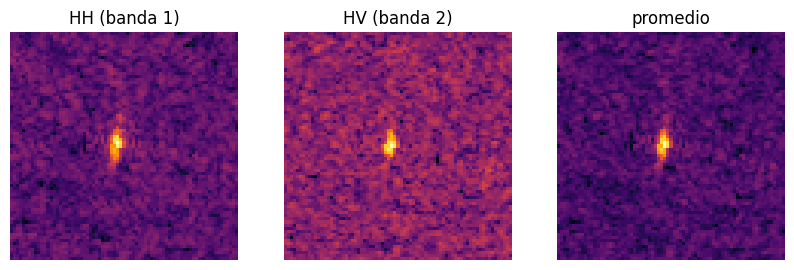

In [5]:
df = cargar_datos()
X = construir_imagenes(df)
y = df["is_iceberg"].values.astype("int64")
print("Tensor de imágenes:", X.shape, X.dtype, f"({X.nbytes / 1e6:.0f} MB)")
print("Etiquetas:", y.shape, "→ iceberg:", y.sum(), "| barco:", (1 - y).sum())
print("Rango de valores (dB): de", round(float(X.min()), 1), "a", round(float(X.max()), 1))

fig, ejes = plt.subplots(1, 3, figsize=(10, 3.4))
for k, nombre in enumerate(("HH (banda 1)", "HV (banda 2)", "promedio")):
    ejes[k].imshow(X[0, :, :, k], cmap="inferno"); ejes[k].set_title(nombre); ejes[k].axis("off")
plt.show()

## 2. Partición entrenamiento / validación

Las imágenes con el mismo `inc_angle` suelen corresponder a la misma pasada del satélite. Si se reparten al azar, versiones casi idénticas del mismo objeto caen en ambos lados y la validación resulta optimista.

Solución: formar **grupos por valor de ángulo** (4 decimales) y usar `StratifiedGroupKFold`, que mantiene la proporción de clases y no separa un grupo. Las imágenes sin ángulo no comparten grupo con ninguna otra.

In [6]:
grupos = grupos_por_angulo(df)
print(f"Grupos distintos: {len(set(grupos))} para {len(df)} imágenes")

def revisar(nombre, idx_tr, idx_val):
    g_tr, g_val = set(grupos[idx_tr]), set(grupos[idx_val])
    solapados = g_tr & g_val
    en_val_con_fuga = np.isin(grupos[idx_val], list(solapados)).mean()
    print(f"{nombre:10s} train={len(idx_tr)}  val={len(idx_val)}  "
          f"iceberg en val={y[idx_val].mean():.1%}  "
          f"ángulos compartidos={len(solapados)}  "
          f"imágenes de val cuyo ángulo está en train={en_val_con_fuga:.1%}")

revisar("ingenua", *particion_ingenua(y, SEMILLA))
idx_tr, idx_val = particion_agrupada(y, grupos, SEMILLA)
revisar("agrupada", idx_tr, idx_val)
assert not (set(grupos[idx_tr]) & set(grupos[idx_val])), "hay ángulos en ambos conjuntos"

Grupos distintos: 1011 para 1604 imágenes
ingenua    train=1283  val=321  iceberg en val=47.0%  ángulos compartidos=100  imágenes de val cuyo ángulo está en train=48.0%
agrupada   train=1281  val=323  iceberg en val=41.5%  ángulos compartidos=0  imágenes de val cuyo ángulo está en train=0.0%


## 3. Normalización

Se estandariza cada canal con la media y la desviación del conjunto de **entrenamiento**; esas mismas constantes se aplican a validación. Calcularlas con todos los datos filtraría información del conjunto de validación.

canal            media(train)  desv(train)   media(val)  desv(val)
HH                 -0.013        1.005        0.003       1.065
HV                  0.166        0.991        0.219       1.022
promedio           -0.035        1.005       -0.000       1.061


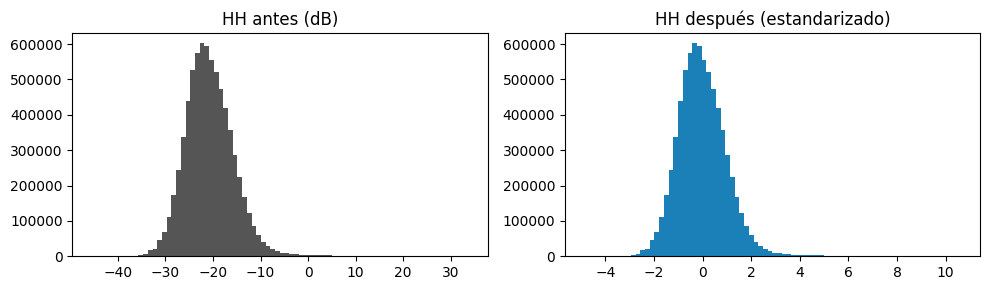

In [7]:
X_tr, X_val = normalizar(X[idx_tr], X[idx_val])
print("canal            media(train)  desv(train)   media(val)  desv(val)")
for k, n in enumerate(("HH", "HV", "promedio")):
    print(f"{n:10s}   {X_tr[..., k].mean():12.3f} {X_tr[..., k].std():12.3f} "
          f"{X_val[..., k].mean():12.3f} {X_val[..., k].std():11.3f}")

fig, ejes = plt.subplots(1, 2, figsize=(10, 3))
ejes[0].hist(X[idx_tr][..., 0].ravel(), bins=80, color="#555"); ejes[0].set_title("HH antes (dB)")
ejes[1].hist(X_tr[..., 0].ravel(), bins=80, color="#1b7fb8"); ejes[1].set_title("HH después (estandarizado)")
plt.tight_layout(); plt.show()

## 4. Aumento de datos

Con solo 1 604 imágenes, el aumento de datos reduce el sobreajuste. Se usan **giros y rotaciones de 90°**, que no alteran la física de una escena SAR vista desde arriba, y se evitan transformaciones que modifican los valores de intensidad (brillo, contraste) o interpolan píxeles (rotaciones arbitrarias), pues esos valores contienen la señal.

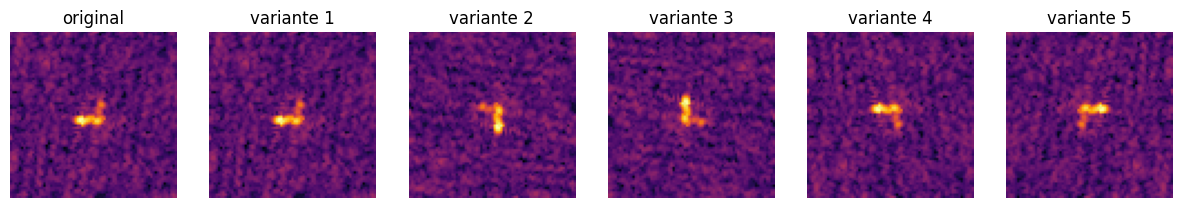

In [8]:
tf.random.set_seed(SEMILLA)
original = tf.constant(X_tr[0])
fig, ejes = plt.subplots(1, 6, figsize=(15, 2.8))
ejes[0].imshow(original[..., 0], cmap="inferno"); ejes[0].set_title("original")
for k in range(1, 6):
    ejes[k].imshow(aumentar(original)[..., 0], cmap="inferno"); ejes[k].set_title(f"variante {k}")
for a in ejes: a.axis("off")
plt.show()

## 5. Pipeline `tf.data`

El conjunto de entrenamiento se baraja y aumenta en cada época; el de validación se deja intacto. Los lotes se prepetchean para solapar la preparación de datos con el entrenamiento. Las entradas son diccionarios con nombre (`imagen`, y `angulo` si se quiere usar como segunda entrada).

In [9]:
ds_tr = crear_dataset(X_tr, y[idx_tr], entrenamiento=True)
ds_val = crear_dataset(X_val, y[idx_val], entrenamiento=False)

entradas, etiquetas = next(iter(ds_tr))
print("Lote de entrenamiento:", {k: tuple(v.shape) for k, v in entradas.items()}, "| etiquetas", tuple(etiquetas.shape))
print("Lotes por época → train:", len(ds_tr), "| validación:", len(ds_val))

t = time.time()
for _ in ds_tr: pass
print(f"Recorrer una época completa del pipeline tarda {time.time() - t:.2f} s")

Lote de entrenamiento: {'imagen': (32, 75, 75, 3)} | etiquetas (32,)
Lotes por época → train: 41 | validación: 11
Recorrer una época completa del pipeline tarda 0.34 s


## 6. Guardar el resultado (opcional)

Para reutilizar el tensor sin repetir la construcción se puede guardar en formato comprimido. La normalización no se guarda a propósito: depende de qué partición se use.

In [10]:
np.savez_compressed("data/iceberg_tensores.npz", X=X, y=y, inc_angle=df["inc_angle"].values, grupos=grupos)
print(f"Guardado data/iceberg_tensores.npz ({os.path.getsize('data/iceberg_tensores.npz') / 1e6:.0f} MB)")

Guardado data/iceberg_tensores.npz (73 MB)


## Resumen

| Paso | Decisión |
|---|---|
| Entrada | 75×75×3 (HH, HV, promedio) |
| Partición | 80/20 estratificada y agrupada por `inc_angle` |
| Normalización | estadísticas de train, por canal |
| Aumento | giros H/V y rotaciones de 90° solo en train |
| `inc_angle` | no se usa como entrada por defecto |